# Hairy Horndeski
$f=1-2M/r+q\,(M/r)\ln(r/2M)$ with $q=Q_H/M$ and prior $\mathcal U[-0.05,0.05]$. 


In [18]:
import sys, copy, warnings, dataclasses
sys.path.insert(0, '..')                      # the package lives one level up
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, torch
import matplotlib.pyplot as plt
%matplotlib inline

from ginn.core import S2Data, keplerian_prefit, LossConfig, train, objective, fit
from ginn.physics import METRICS
from ginn import analysis as an
from ginn import plotting as pl

data = S2Data.from_csv('../data/tab_gillessen_pos.csv', '../data/tab_gillessen_vr.csv')
print(data.summary())

Gillessen+2017: 145 astrometric epochs, 44 RVs, 1992.22-2016.53;  N_data = 334


In [19]:
N_STEPS_GINN   = 3000        # joint fit: orbit + hair + network
N_STEPS_KEPLER = 2000        # no network pretraining
N_STEPS_EXACT  = 1500        # exact-solver reference fit

MODEL = dict(hidden=(32, 32),        # network with 2 hidden tanh layers of 32, output in radians
             nn_out_scale=1e-3)

TRAIN = dict(lr_u=0.1,               # Adam step, u = list of model parameters 
             lr_nn=5e-4,             # Adam step, network weights  - larger values will give large spikes in the loss
             lr_floor=0.01,          # cosine decay to lr_floor x initial
             precondition=(0.0,))    # Gauss-Newton preconditioner computed once at step 0

cfg = LossConfig(eps_phys=1e-4,      # physics loss weight (tolerance) - tested, or in validation notebook
                 n_colloc=256,       # collocation points over one radial period
                 sigma_w=10.0)       # weak Gaussian prior on network weights (for Laplace)
FRAME = ['x0', 'y0', 'vx0', 'vy0', 'vz0']
LIT = {'inc': 134.18, 'Omega': 226.94, 'omega': 65.51}   # just for pretraining - we do not need any other parameters even here. 

#------------------- choose metric here 

METRIC    = 'hairy_horndeski'

HAIR_INIT = {'q': 0.001}   # its important to start slight away from GR because at GR some hair directions have zero gradient

#-------------------not important - just some checks (only in Yukawa it is)
FIXED     = ()        
SCAN      = None   # optional (name, [values]) of a fixed parameter to repeat the fit 
N_STEPS_WARM = 1000        # (SCAN only) re-fit of orbit + network at each new value
HOLD_HAIR_IN_ADAM = False  # False: hair free in Adam and in the polish.
                           # True: hair held during Adam, freed for the polish (only needed if Adam drives the hair far off, like in Yukawa with lambda free).

GN = dict(n_iter=30,       # max Gauss-Newton polish steps (it stops when converged but maximum is 30 - change if nessecary)
          n_retrain=400,   # network re-training between steps (hair held)
          tol=0.02,        # stop when the predicted chi2 gain < tol
          lr_nn=2e-3)      # faster network step during training
USE_FSP = False            # set it to True if you want to use precession data f_SP = 1.10 +- 0.19

CORNER = dict(n_samples=200_000,   # Laplace samples (more samples gives smoother contours)
              bins=40,             # histogram bins per axis
              smooth=1.5)          # Gaussian smoothing of the 2-D histograms (in bins)
metric = METRICS[METRIC]
if USE_FSP:
    cfg = dataclasses.replace(cfg, external_precession=(1.10, 0.19))
HOLD = tuple(hp.name for hp in metric.hair if hp.name not in FIXED)
for hp in metric.hair: print(hp)

HairParam(name='q', latex='$q_H$', prior=Uniform(-0.05, 0.05), init=0.001, scale=0.001, gr_value=0.0)


### Not important: compare analytic precession vs the numerical

In [20]:


# from ginn.physics import orbit_constants, M_SUN_GEOM_AU
# M_, a_, e_ = torch.tensor(4.26e6 * M_SUN_GEOM_AU), torch.tensor(1031.2), torch.tensor(0.8846)
# gr = 6 * np.pi * M_ / (a_ * (1 - e_**2))
# for hp in metric.hair:
#     for v in np.linspace(hp.prior.lo, hp.prior.hi, 5):
#         par = {h.name: torch.tensor(float(v if h.name == hp.name else HAIR_INIT.get(h.name, h.init))) for h in metric.hair}
#         d = orbit_constants(metric, a_, e_, par, M_)[3]; an_ = metric.precession(M_, a_, e_, par)
#         print(f"{hp.name} = {v:9.4g}: f_SP exact {(d/gr).item():9.4f}   analytic {(an_/gr).item():9.4f}")

## Pretraining and Adam joint fit

Keplerian pre-fit (astrometry only): chi2 = 297.4
  M=4.1419e+06, a=1023.6, e=0.87929, inc=134.79, Omega=224.95, omega=63.536, t0=2002.3, D=8.3, P=16.0909 yr


hairy_horndeski/ginn:   0%|          | 0/3000 [00:00<?, ?it/s]

after Adam: M = 4.2822e6 Msun | a = 1031.26 AU | e = 0.88621 | i = 134.084 | Om = 227.317 | om = 65.658 | t_p = 2002.3264 | D = 8.0882 kpc | vz0 = 11.69 km/s
   frame: x0 = +0.690 mas | y0 = -2.431 mas | vx0 = +0.1712 mas/yr | vy0 = +0.0284 mas/yr | q = 0.003211


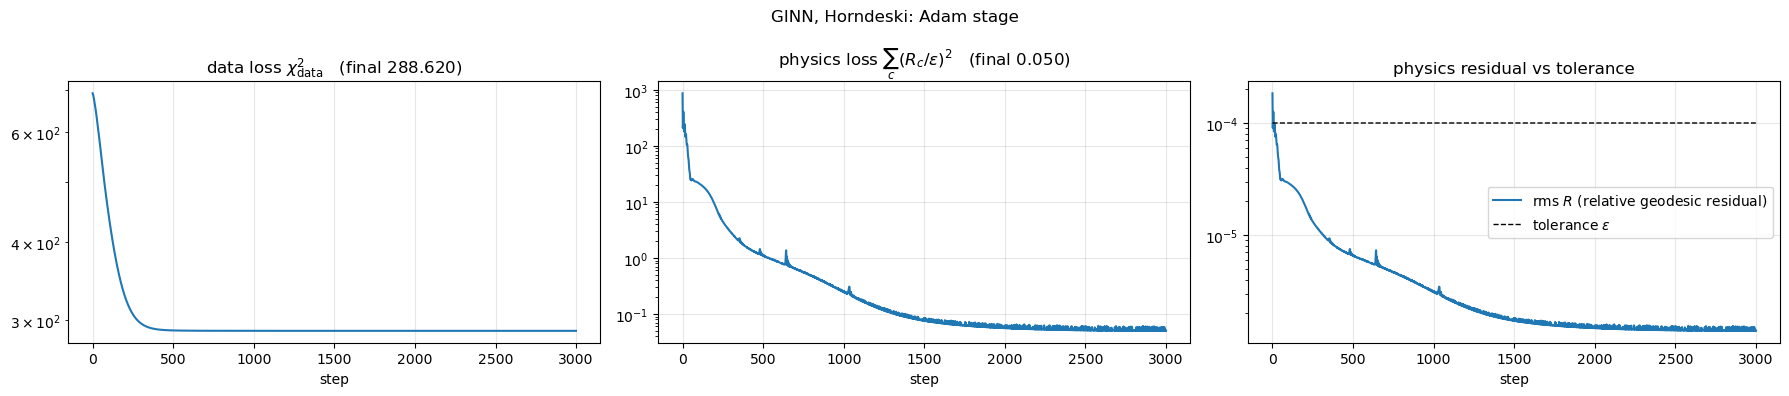

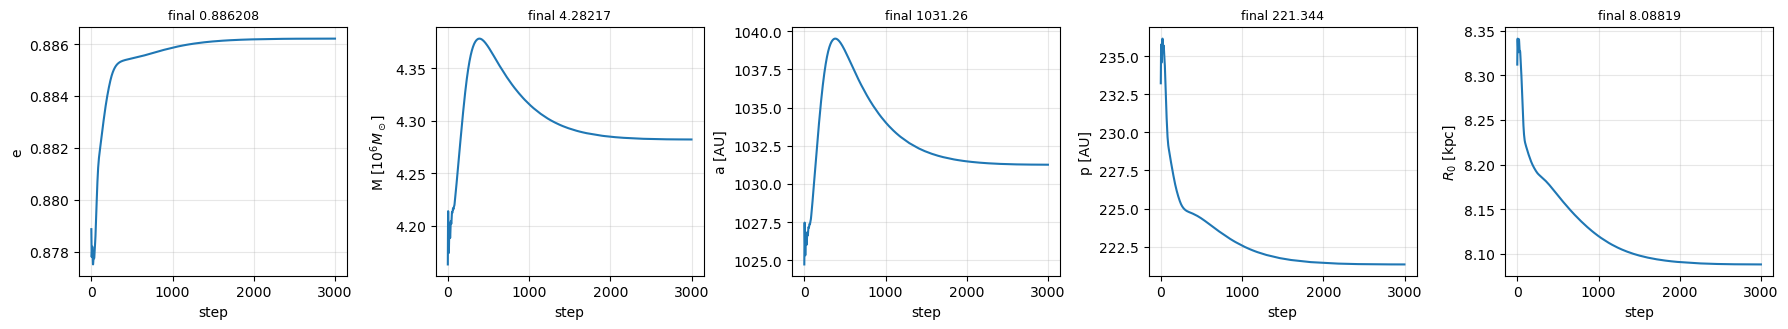

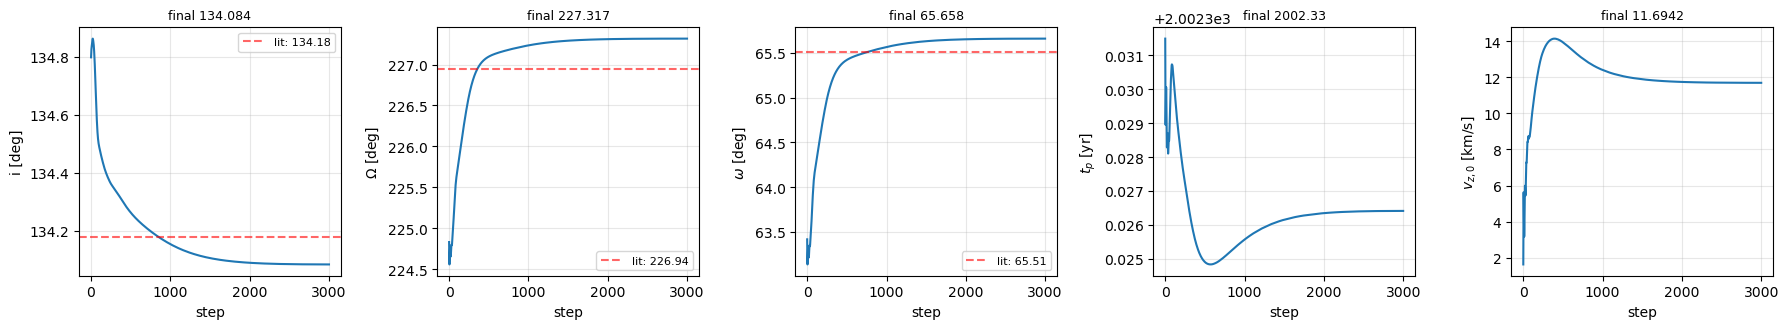

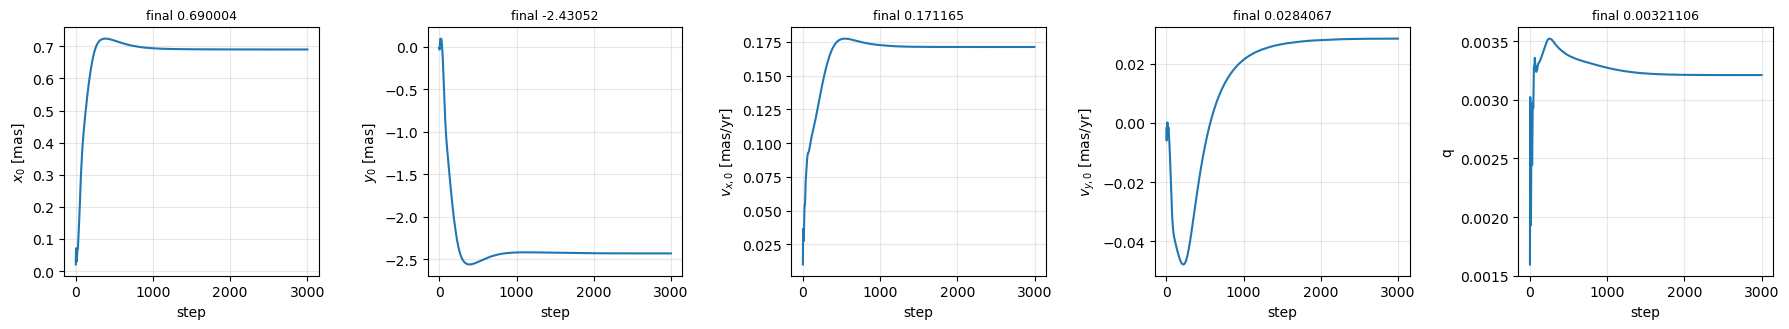

In [21]:
init = keplerian_prefit(data)
ginn, hist = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN,
                 hair_init=HAIR_INIT, fixed=tuple(set(HOLD) | set(FIXED)) if HOLD_HAIR_IN_ADAM else FIXED,
                 **MODEL, **TRAIN)
if HOLD_HAIR_IN_ADAM:
    for h in HOLD:
        ginn.fix(h, fixed=False)                 # release the hair for the polish
print('after Adam:', ginn.summary())
pl.plot_loss_history(hist, f'GINN, {metric.label}: Adam stage'); plt.show()
pl.plot_param_history(hist, lit=LIT); plt.show()

## Gauss–Newton polish

Here we do a local approximation: near the current parameters, we replace the loss by a parabola (a quadratic function), and the step jumps to that parabola's minimum. This is done in between the Adam run. We can compute how much loss would drop (given by $[g_m]^T [H_m]^{-1} g_m$) if this parabola were exact. 
For a small step $\Delta$ in the parameters, each residual changes approximately linearly $r + J \Delta$ (J is a Jacobian). Putting this into the loss:

$L(u + \Delta) ≈ |r + J\Delta|^2 = r^Tr + 2 g^T\Delta + \Delta^T H \Delta$

with $g = J^T r$ and $H = J^T J$ is the Gauss–Newton curvature. That is the quadratic model a constant, a linear term which is the slope and a quadratic curvature term.

GN 0: predicted chi2 gain    0.137   q = 0.003211
GN 1: predicted chi2 gain    1.053   q = 0.004547
GN 2: predicted chi2 gain    0.131   q = 0.0047572
GN 3: predicted chi2 gain    0.041   q = 0.0048001
GN 4: predicted chi2 gain    0.026   q = 0.0048395
GN 5: predicted chi2 gain    0.010   q = 0.0048638

after polish: M = 4.3339e6 Msun | a = 1033.05 AU | e = 0.88551 | i = 134.112 | Om = 227.243 | om = 65.503 | t_p = 2002.3250 | D = 8.1072 kpc | vz0 = 12.69 km/s
   frame: x0 = +0.674 mas | y0 = -2.385 mas | vx0 = +0.1975 mas/yr | vy0 = +0.0351 mas/yr | q = 0.004864


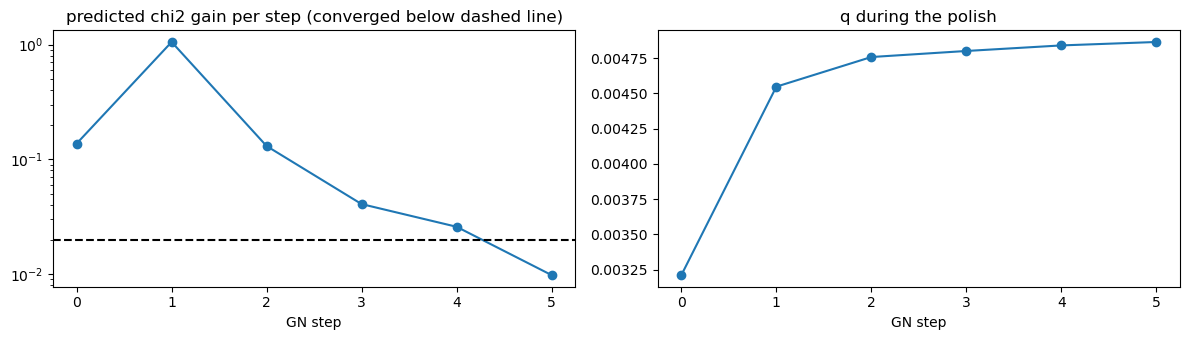

In [22]:
lap, gn_hist = an.gn_polish(ginn, data, cfg, **GN)
print('\nafter polish:', ginn.summary())
if HOLD:
    fig, ax = plt.subplots(1, 1 + len(HOLD), figsize=(6 * (1 + len(HOLD)), 3.5))
    ax[0].semilogy([max(h['chi2_gain'], 1e-4) for h in gn_hist], 'o-'); ax[0].axhline(GN['tol'], color='k', ls='--')
    ax[0].set_title('predicted chi2 gain per step (converged below dashed line)'); ax[0].set_xlabel('GN step')
    for a_, h in zip(ax[1:], HOLD):
        a_.plot([x[h] for x in gn_hist], 'o-'); a_.set_title(f'{h} during the polish'); a_.set_xlabel('GN step')
    plt.tight_layout(); plt.show()

In [23]:
# This plot shows the Gauss–Newton stage that follows Adam
# At each step the code predicts how much chi-squared would still drop if it moved to the minimum of the local quadratic model
# It is a measure of how far from the minimum the fit still is.

# Size of the move is about 0.0016 in q, which roughly 0.45σ for σ ≈ 0.0035.
# The gain in chi-squared is small compared to 288.

# So Adam still gets everything right. The polish helps in addition

# The flattening curve shows the convergence. 



## Results

In [24]:
post = an.posterior(ginn, data, cfg)
est = an.print_estimates(ginn, post)
S = an.sample_laplace(ginn, post, n=CORNER['n_samples'])
print()
for k in ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME:
    m_, lo_, hi_ = an.summarize(S)[k]; print(f"{k:6s} = {m_:.6g} +- {0.5 * (lo_ + hi_):.3g}")

             q = 0.0048638 +- 0.0038   (1.3 sigma from GR)
[sample_laplace] 100.0% of samples inside the hair prior (the rest are rejected = Laplace x prior).

M      = 4.33462 +- 0.251
D      = 8.10734 +- 0.226
a      = 127.421 +- 1.36
e      = 0.885506 +- 0.00305
inc    = 134.114 +- 0.545
Omega  = 227.244 +- 0.729
omega  = 65.5035 +- 0.773
t0     = 2002.32 +- 0.00694
x0     = 0.673499 +- 0.225
y0     = -2.38534 +- 0.669
vx0    = 0.197471 +- 0.0762
vy0    = 0.0350204 +- 0.0759
vz0    = 12.677 +- 8


In [25]:
# save the best fit and its posterior (used by compare_orbits.ipynb and 00_validation_and_checks.ipynb)
import os
os.makedirs('results', exist_ok=True)
torch.save(dict(model=ginn, hair=est, post=post, cfg=cfg), f'results/{METRIC}.pt')
print(f'saved results/{METRIC}.pt')

saved results/hairy_horndeski.pt


## Bayesian evidence
Laplace estimate of the evidence, from the same curvature as the error bars, relative to Schwarzschild (run 01_schwarzschild first). $\ln B>0$ favours this spacetime; the Occam term depends on the width of the hair prior.

In [26]:
ev = an.evidence(ginn, data, cfg, post)
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['evidence'] = ev
torch.save(r_, f'results/{METRIC}.pt')
ref_file = 'results/schwarzschild.pt'
ref = torch.load(ref_file, weights_only=False) if os.path.exists(ref_file) else {}
if METRIC == 'schwarzschild':
    print(f"chi2 = {ev['chi2']:.3f},   ln det Sigma = {ev['logdet_rest']:.3f}   (reference for all Bayes factors)")
elif 'evidence' in ref:
    an.print_bayes(metric.label, an.bayes_factor(ev, ref['evidence']))
else:
    print('run 01_schwarzschild.ipynb first: it provides the reference evidence')

model               dchi2  ln Occam  dln vol    ln B   evidence
Horndeski           -1.57     -2.35     0.01   -1.56   weak for Schwarzschild


## Corner plots

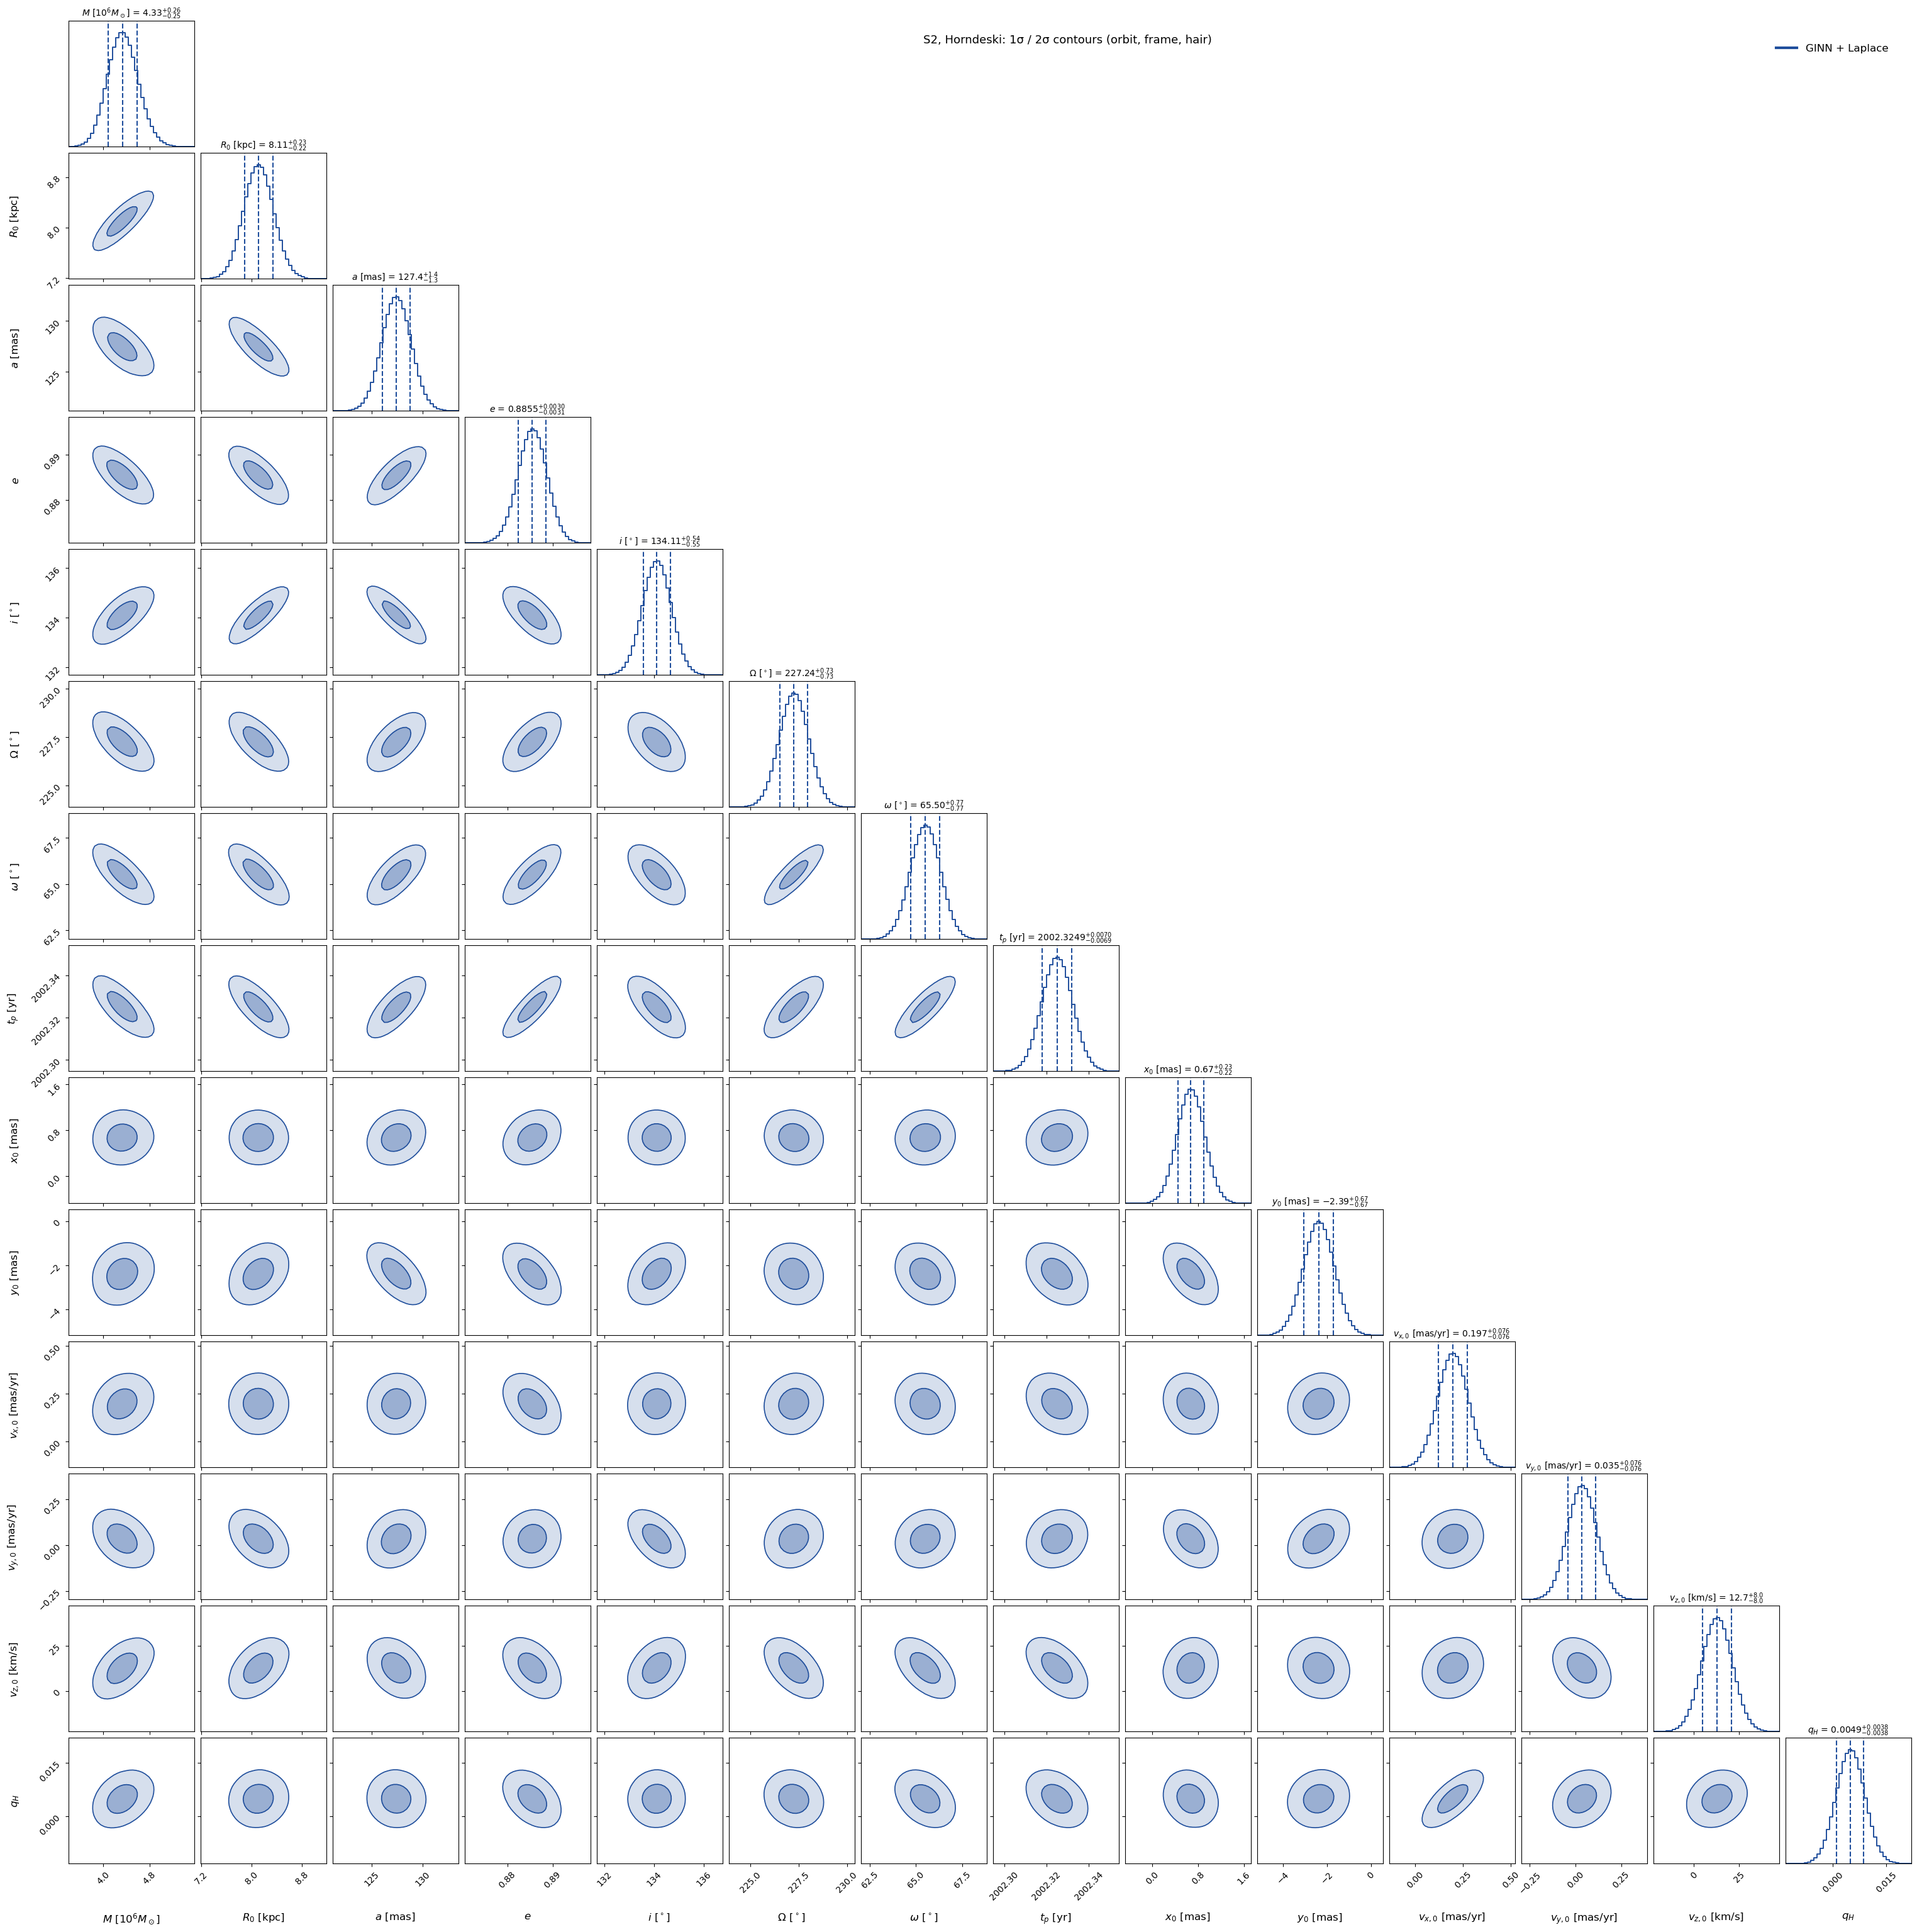

In [27]:
# one corner plot with ALL fitted parameters: orbit, hair and reference-frame offsets
keys = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + FRAME + list(HOLD)   # ALL parameters, one plot
pl.corner_plot([S], an.labels_for(ginn), keys, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: 1σ / 2σ contours (orbit, frame, hair)')
plt.savefig("corner_02_hairy_horndeski.png")
plt.show()

### Reduced corner plot: mass, orbital elements and hair

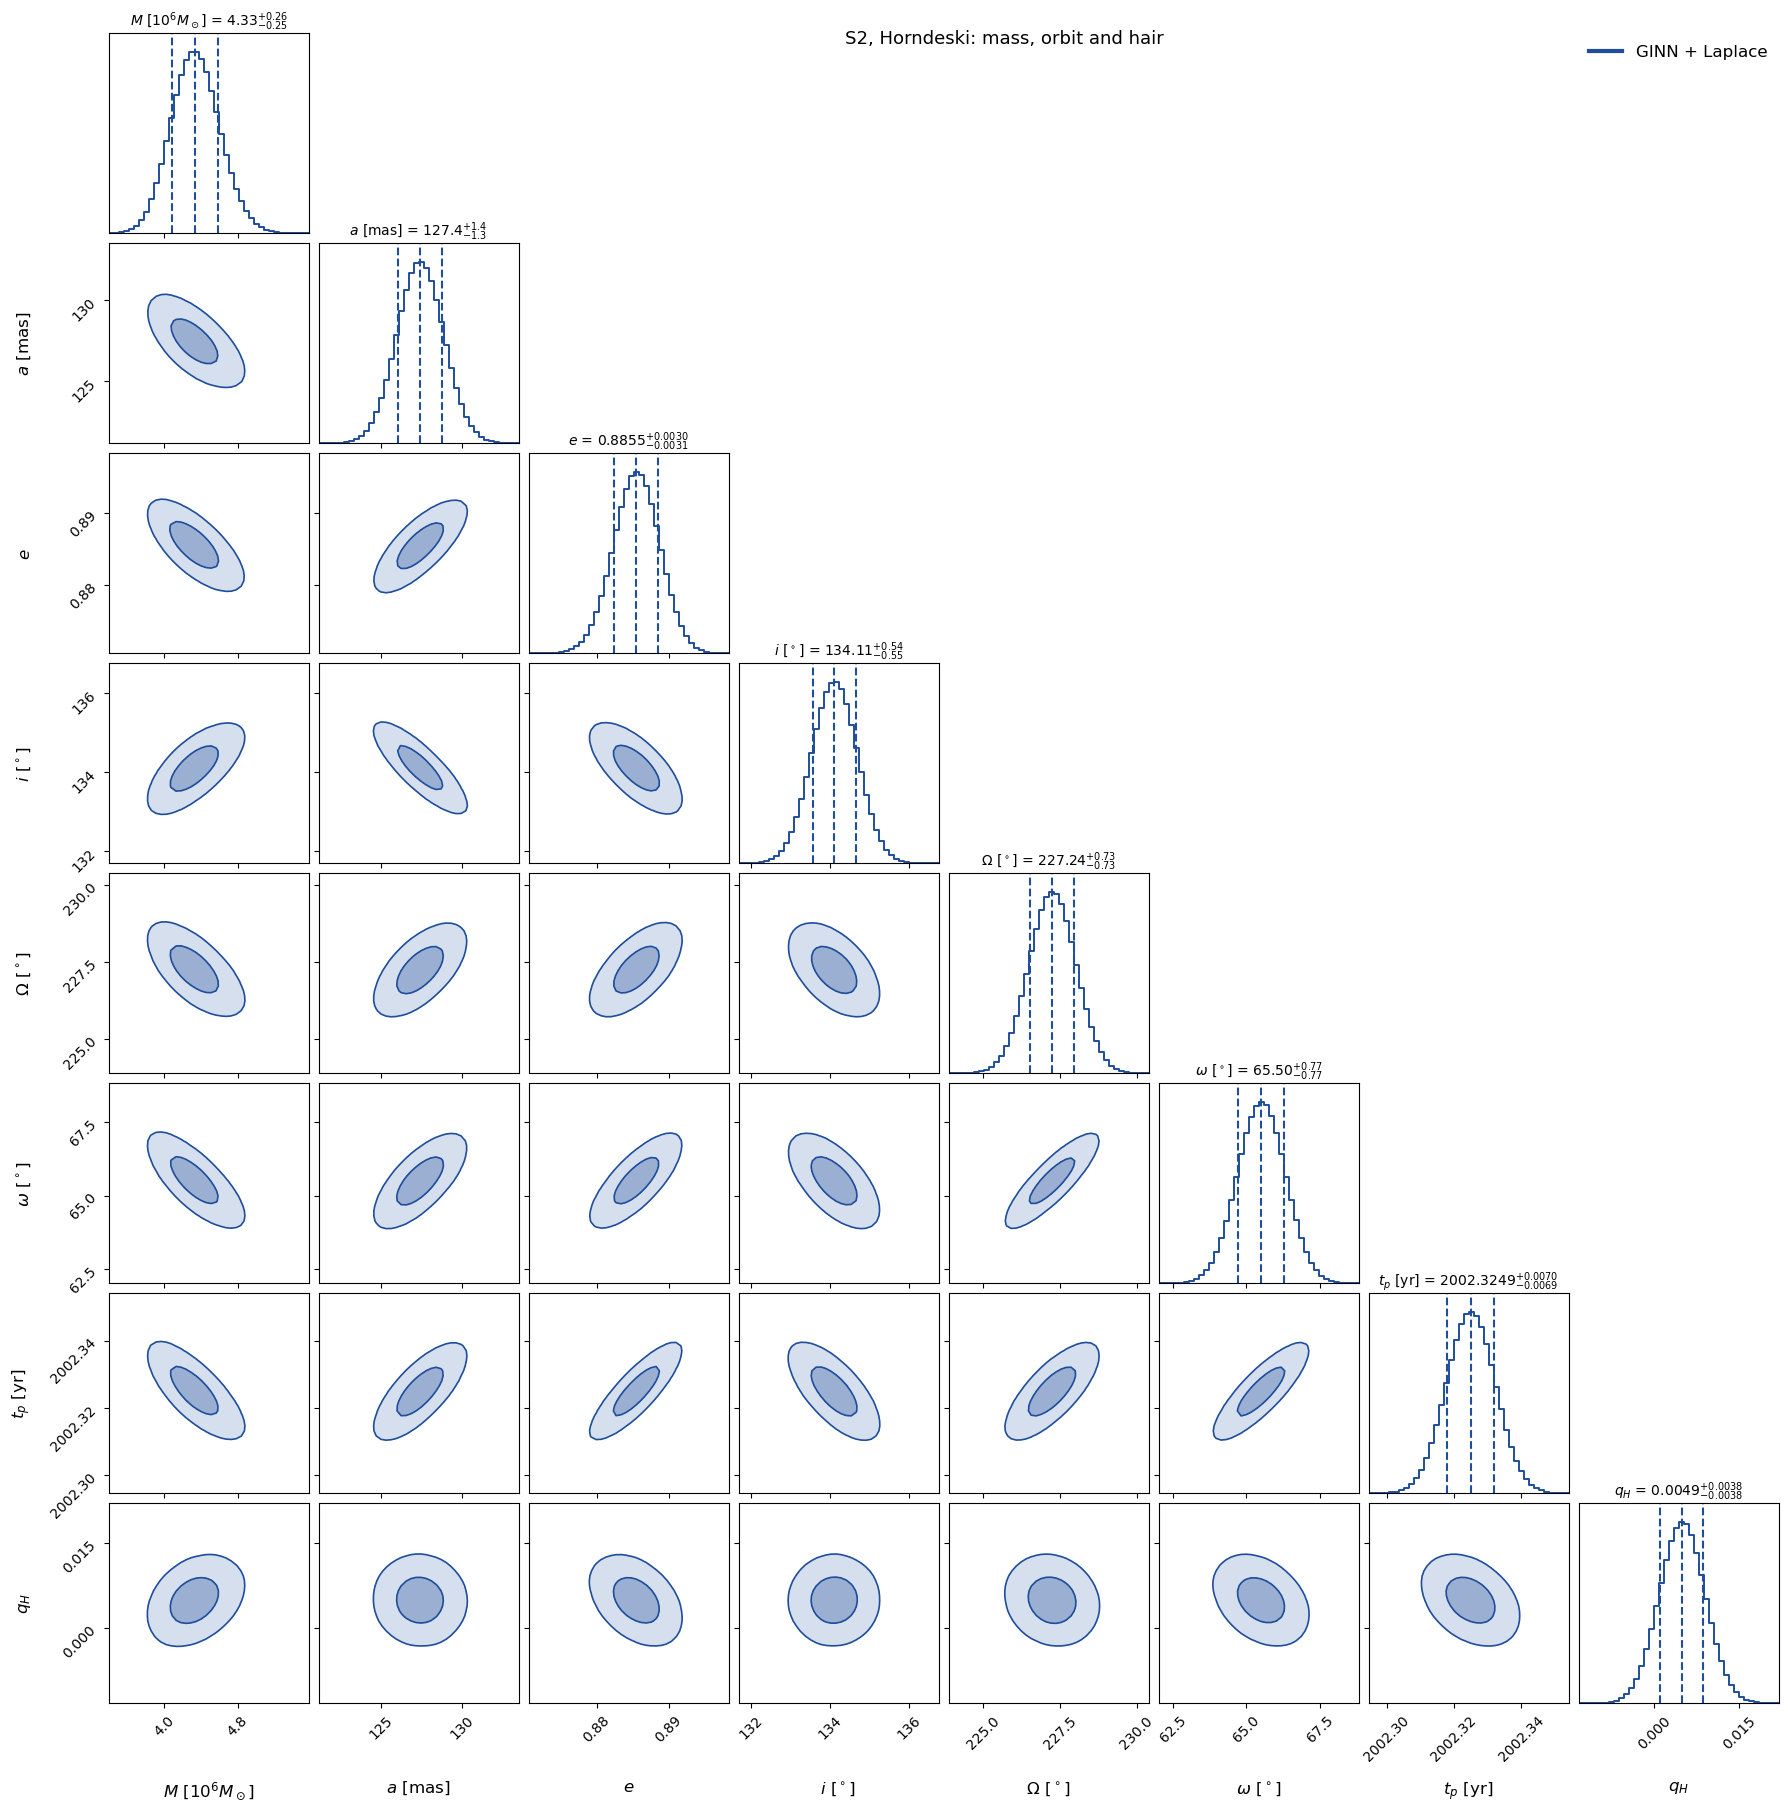

In [28]:
keys_red = ['M', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
pl.corner_plot([S], an.labels_for(ginn), keys_red, names=['GINN + Laplace'],
               bins=CORNER['bins'], smooth=CORNER['smooth'],
               title=f'S2, {metric.label}: mass, orbit and hair')
plt.savefig("small_corner_02_hairy_horndeski.png")
plt.show()

In [29]:
#pl.plot_convergence(hist, S, gn_hist if HOLD else None, title=f'{metric.label}: convergence'); plt.show()

In [30]:
# keep the posterior samples for the summary plots in 09_compare_orbits
import os
res_file = f'results/{METRIC}.pt'
if os.path.exists(res_file):
    r_ = torch.load(res_file, weights_only=False)
    r_['samples'] = {k: np.asarray(v)[:20000] for k, v in S.items()}
    torch.save(r_, res_file)

## Beyond the quadratic approximation
The data residuals are expanded to second order in the physical parameters, with the network eliminated to the same order, so that $\chi^2$ contains terms up to fourth order. This posterior is sampled with MCMC and compared with the Gauss–Newton + Laplace result above: shifts of the mean in units of the Laplace $\sigma$, ratio of the widths, and skewness. The comparison with the exact geodesic solver is in 00_validation_and_checks.

The chain is shorter than 50 times the integrated autocorrelation time for 1 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 194;
tau: [192.39577521 175.1128739  173.82953076 205.95187149 182.51206422
 178.79633556 167.64731049 173.59700068 167.53287429 176.79791488
 184.68512375 166.47455837 168.55662687 179.47182361]


higher-order MCMC: 2641 effective samples

             Gauss-Newton + Laplace |        dali: shift, sd ratio, skew
M               4.34114 +- 0.251     |      -0.02       0.947       +0.15 |
D               8.11022 +- 0.226     |      -0.04       0.943       +0.03 |
a               127.434 +- 1.36      |      +0.04       0.947       +0.17 |
e              0.885483 +- 0.00306   |      +0.02       0.941       +0.05 |
inc             134.112 +- 0.545     |      -0.02       0.944       -0.04 |
Omega           227.245 +- 0.729     |      +0.02       0.953       -0.00 |
omega           65.5046 +- 0.775     |      +0.01       0.940       +0.01 |
t0              2002.32 +- 0.00696   |      -0.02       0.938       -0.09 |
q            0.00486066 +- 0.0038    |      +0.02       1.008       -0.07 |

q: 95% interval  Gauss-Newton + Laplace [-0.002576, +0.01232]   dali [-0.002719, +0.0123]


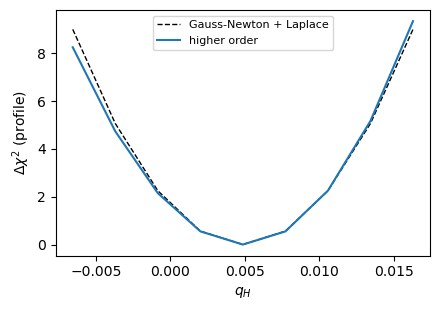

In [31]:
from ginn import higher_order as ho
HO_KEYS = ['M', 'D', 'a', 'e', 'inc', 'Omega', 'omega', 't0'] + list(HOLD)
P = ho.Expansion(ginn, data, post, cfg).expand()
chain = ho.sample(P, 'dali', n=600_000)
st = {'laplace': ho.stats(ho.sample(P, 'laplace'), HO_KEYS), 'dali': ho.stats(chain, HO_KEYS)}
print(f"higher-order MCMC: {chain['n_eff']:.0f} effective samples\n")
ho.print_compare(st, HO_KEYS, names=('dali',), hair=list(HOLD))
names = list(HOLD) or ['logM']
fig, axs = plt.subplots(1, len(names), figsize=(4.5 * len(names), 3.2), squeeze=False)
for a_, nm in zip(axs[0], names):
    pr = ho.profile(P, nm)
    if nm == 'logM':
        ho.plot_profile(a_, pr, label=r'$M\ [10^6 M_\odot]$', transform=lambda x: np.exp(x) / 1e6)
    else:
        ho.plot_profile(a_, pr, label=an.labels_for(ginn)[nm])
axs[0][0].legend(fontsize=8); plt.tight_layout(); plt.show()
r_ = torch.load(f'results/{METRIC}.pt', weights_only=False)
r_['higher_order'] = st
torch.save(r_, f'results/{METRIC}.pt')

## Role of the network
we compare network vs the exact numerical geodesic at the fitted parameters

chi2 (N_data = 334)                     RA      Dec      RV     total
  GINN                                         139.57   137.40   11.47   288.437
  without network                              139.57   137.61   11.49   288.672
  geodesic timing numerical                    139.57   137.40   11.47   288.437
we compare chi-squared improvement due to GINN and exact numerical correction - should be more or less equal


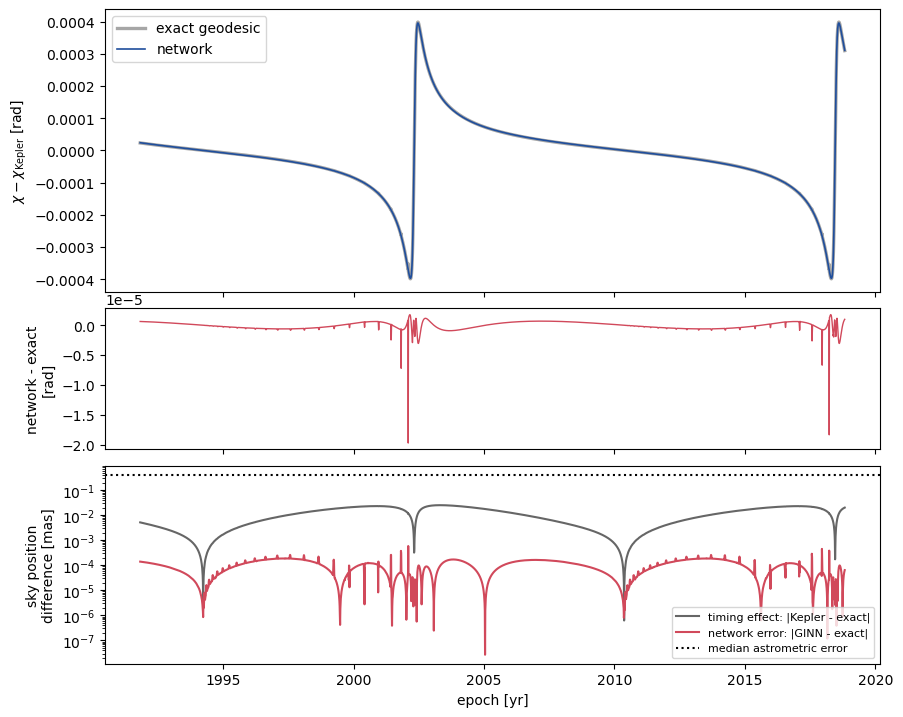

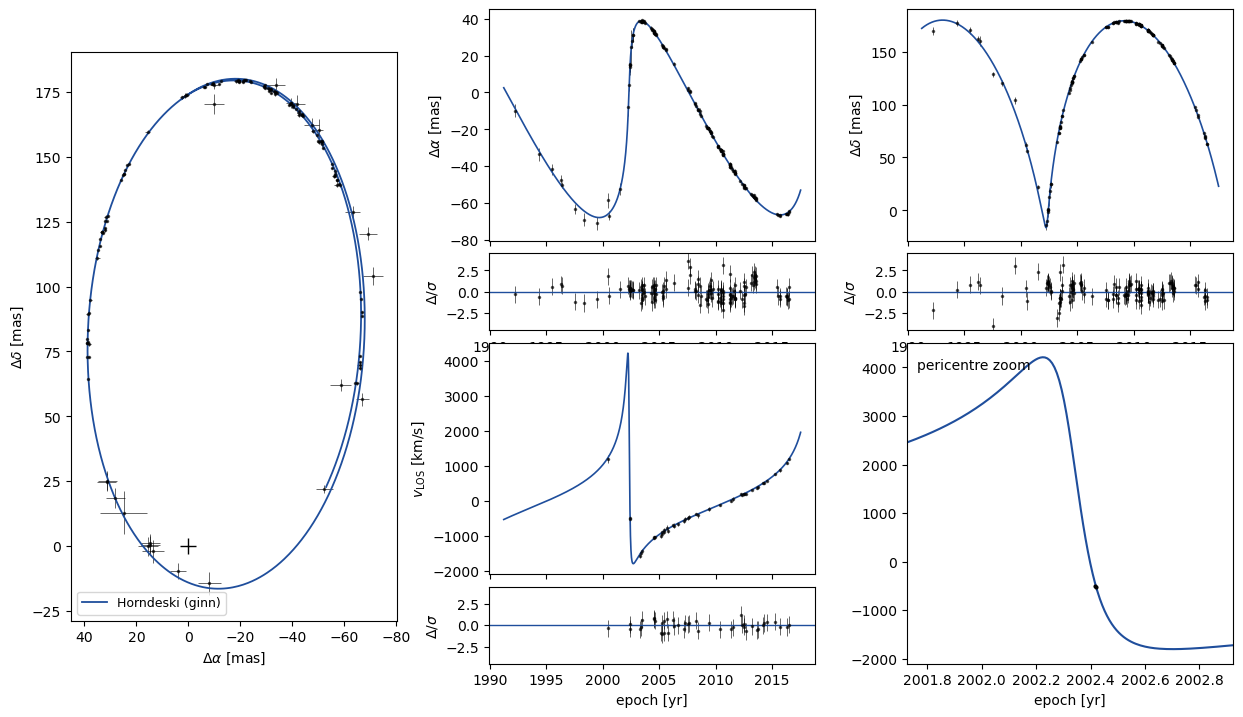

In [32]:
rep = an.nn_role_report(ginn, data, cfg, lap=post)
pl.plot_timing(rep['timing_curves'], data); plt.show()
pl.plot_fit(ginn, data); plt.show()

In [33]:
# Cross-check with the exact geodesic solver -not important

# exact, _ = fit(metric, data, init, timing='exact', cfg=cfg, n_steps=N_STEPS_EXACT,
#                hair_init=HAIR_INIT, fixed=FIXED, **TRAIN)
# lap_ex = an.laplace(exact, data, cfg)
# print('exact solver:', exact.summary())
# print('exact solver hair:', an.hair_estimates(exact, lap_ex))

## Consistency test

The full procedure (Adam, then Gauss–Newton polish, then Laplace) is run again from a few starting values of the hair parameter to check we get the consistent result. The estimate is accepted only if the spread of the final values is < 0.2 sigma.


start -0.01: q: Adam +0.0065009 -> polish +0.0051163 +- 0.00378  | M = 4.2909, R0 = 8.0632 | chi2 Adam 394.01 -> 288.45 (3 GN steps)
start +0.001: q: Adam +0.003211 -> polish +0.0048638 +- 0.0038  | M = 4.3353, R0 = 8.1097 | chi2 Adam 288.62 -> 288.44 (6 GN steps)
start +0.01: q: Adam +0.0034149 -> polish +0.0048448 +- 0.00378  | M = 4.3259, R0 = 8.1024 | chi2 Adam 295.77 -> 288.43 (7 GN steps)

             q: spread across starts = 0.07 sigma  ->  CONSISTENT
             M: spread across starts = 0.18 sigma  ->  CONSISTENT
            R0: spread across starts = 0.21 sigma  ->  NOT CONSISTENT (increase N_STEPS_GINN or GN n_iter)


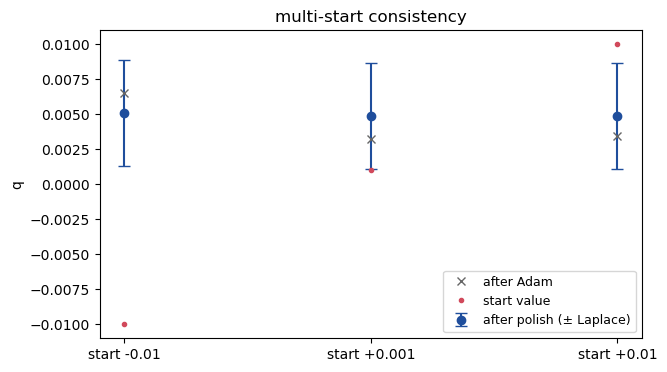

In [34]:
RUN_MULTISTART = True
MULTI_STARTS = [-0.01, 0.001, 0.01]
ms_rows = []
if RUN_MULTISTART:
    for s0 in MULTI_STARTS:
        if HOLD:
            hi, seed = {**HAIR_INIT, HOLD[0]: s0}, 0
        else:
            hi, seed = HAIR_INIT, int(s0)
        m_, h_ = fit(metric, data, init, timing='ginn', cfg=cfg, n_steps=N_STEPS_GINN, hair_init=hi,
                     fixed=FIXED, seed=seed, progress=False, **MODEL, **TRAIN)
        adam = {k: float(m_.physical()['par'][k]) for k in HOLD}
        chi2_adam = an.chi2_parts(m_, data)['total']
        lap_, gh_ = an.gn_polish(m_, data, cfg, verbose=False, **GN)
        post_ = an.posterior(m_, data, cfg, verbose=False)
        S_ = an.sample_laplace(m_, post_, n=20000, verbose=False)
        row = dict(start=s0, adam=adam, chi2_adam=chi2_adam, est=an.hair_estimates(m_, post_),
                   chi2=an.chi2_parts(m_, data)['total'], steps=len(gh_),
                   M=an.summarize(S_)['M'], D=an.summarize(S_)['D'])
        ms_rows.append(row)
        txt = '  '.join(f"{k}: Adam {row['adam'][k]:+.5g} -> polish {row['est'][k][0]:+.5g} +- {row['est'][k][1]:.3g}" for k in HOLD)
        print(f"start {s0:+g}: {txt}  | M = {row['M'][0]:.4f}, R0 = {row['D'][0]:.4f} | chi2 Adam {chi2_adam:.2f} -> {row['chi2']:.2f} ({row['steps']} GN steps)")
    def spread(vals, sig):
        return (max(vals) - min(vals)) / sig
    sym = lambda k, v: abs(v) if k in an.SQUARED_HAIR else v
    checks = [(k, [sym(k, r['est'][k][0]) for r in ms_rows], np.mean([r['est'][k][1] for r in ms_rows])) for k in HOLD]
    checks += [('M', [r['M'][0] for r in ms_rows], np.mean([0.5 * (r['M'][1] + r['M'][2]) for r in ms_rows])),
               ('R0', [r['D'][0] for r in ms_rows], np.mean([0.5 * (r['D'][1] + r['D'][2]) for r in ms_rows]))]
    print()
    for k, vals, sig in checks:
        sp = spread(vals, sig)
        print(f"{k:>14s}: spread across starts = {sp:.2f} sigma  ->  " +
              ('CONSISTENT' if sp < 0.2 else 'NOT CONSISTENT (increase N_STEPS_GINN or GN n_iter)'))
    if HOLD:
        k = HOLD[0]
        fig, ax = plt.subplots(figsize=(7, 4))
        xs = np.arange(len(ms_rows))
        ax.errorbar(xs, [r['est'][k][0] for r in ms_rows], [r['est'][k][1] for r in ms_rows], fmt='o',
                    color='#1f4e9c', capsize=4, label='after polish (± Laplace)')
        ax.plot(xs, [r['adam'][k] for r in ms_rows], 'x', color='0.4', label='after Adam')
        ax.plot(xs, [r['start'] for r in ms_rows], '.', color='#d1495b', label='start value')
        ax.set_xticks(xs); ax.set_xticklabels([f"start {r['start']:+g}" for r in ms_rows])
        ax.set_ylabel(k); ax.legend(fontsize=9); ax.set_title('multi-start consistency'); plt.show()